In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# DAT 262 — Capítulo 6: SARIMA sobre 7 días completos de GH Archive (versión final)

Lee los **7 archivos diarios** `AAAA-MM-DD.json.gz` (10-mar-2026 a 16-mar-2026) que ya descargaste, cuenta los eventos **por hora** y modela la serie horaria (168 observaciones, ciclo estacional $s=24$) con el ciclo completo de Box–Jenkins.

**Qué hace, en orden**
1. Localiza la carpeta `gharchive_gz` en tu Drive (aunque la hayas movido) y comprueba que estén los 7 archivos.
2. Cuenta los eventos de cada una de las 168 horas, **leyendo cada archivo una sola vez**, sin CSV intermedio.
3. Capítulo 6 paso a paso: no estacionariedad y diferenciación (6.1), Dickey–Fuller y KPSS (6.1.1), Box–Jenkins (6.2), pronóstico ARIMA (6.3) y SARIMA (6.4).
4. Guarda **todas las figuras y resultados** en la carpeta `resultados_sarima/`, con `metricas.json` generado por el código, y la comprime en un `.zip` para descargarla a tu computadora.

**Definición de la serie:** $y_t$ = número de eventos del archivo horario $t$ de GH Archive (UTC). Se modela $\log y_t$ porque la amplitud del ciclo diario crece con el nivel.

## 0. Librerías y parámetros

In [1]:
import os, io, sys, gzip, json, zlib, time, shutil, platform, warnings, zipfile, pickle
from pathlib import Path
from datetime import datetime, timezone, timedelta
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, statsmodels, sklearn
from scipy import stats

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera
from sklearn.metrics import mean_absolute_error, mean_squared_error

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(it=None, **k): return it
try:
    from IPython.display import display
except ImportError:
    display = print

# ---------------- DATOS ----------------
RUTA_GZ = None            # None = buscar sola la carpeta gharchive_gz en tu Drive.
                          # Si prefieres, pon la ruta exacta, p. ej. "/content/drive/MyDrive/DAT-262 procesos estocásticos/gharchive_gz"
FECHA_INICIO = "2026-03-10"
N_DIAS = 7
MONTAR_DRIVE = True       # monta Google Drive si estás en Colab
HILOS = 3                 # archivos que se leen a la vez
USAR_CACHE = True         # guarda el conteo por hora en un JSON pequeño junto a los .gz; así no se vuelve a leer 5 GB

# ---------------- MODELO ----------------
S = 24                    # período estacional: 24 horas
H = 24                    # horizonte de validación: el último día (24 h)
ALPHA = 0.05
RAPIDO = False            # True = grilla más pequeña (p,q ∈ {0,1}); útil para probar

# ---------------- SALIDA ----------------
NOMBRE_RES = "resultados_sarima"
COPIAR_A_DRIVE = True     # deja también una copia de la carpeta en Drive (junto a los .gz)
DESCARGAR_ZIP = True      # al final descarga el .zip a tu computadora

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB and MONTAR_DRIVE and not Path("/content/drive/MyDrive").exists():
    from google.colab import drive
    drive.mount("/content/drive")

BASE = Path("/content") if EN_COLAB else Path(".")
RES = BASE / NOMBRE_RES
FIG, TAB = RES / "figuras", RES / "tablas"
for p in (FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)

M = {}   # aquí se acumula todo lo que termina en metricas.json

def guardar(nombre, fig=None):
    """Guarda la figura actual en resultados_sarima/figuras/ (antes de plt.show())."""
    (fig or plt.gcf()).savefig(FIG / f"{nombre}.png", dpi=150, bbox_inches="tight")

print(f"Resultados se guardarán en: {RES.resolve()}")

Mounted at /content/drive
Resultados se guardarán en: /content/resultados_sarima


## 1. Localizar los 7 archivos diarios

Como moviste los archivos, la celda busca `gharchive_gz` dentro de tu Drive (primero en carpetas `DAT-262*`, luego en un barrido de hasta 4 niveles). Si `RUTA_GZ` tiene valor, usa esa ruta sin buscar. Después comprueba que existan exactamente los 7 archivos esperados y que no haya restos de descargas incompletas (`.part`, `.progreso`).

In [2]:
def ubicar_carpeta():
    if RUTA_GZ:
        p = Path(RUTA_GZ)
        if not p.is_dir():
            raise FileNotFoundError(f"RUTA_GZ no existe: {p}")
        return p
    raiz = Path("/content/drive/MyDrive")
    if not raiz.exists():
        raise FileNotFoundError("No encuentro /content/drive/MyDrive. Monta Drive o define RUTA_GZ.")
    candidatas = sorted(raiz.glob("DAT-262*/gharchive_gz")) + [raiz / "gharchive_gz"]
    for c in candidatas:
        if c.is_dir() and any(c.glob("*.json.gz")):
            return c
    for actual, subdirs, _ in os.walk(raiz):
        if len(Path(actual).relative_to(raiz).parts) >= 4:
            subdirs[:] = []
            continue
        if "gharchive_gz" in subdirs and any((Path(actual) / "gharchive_gz").glob("*.json.gz")):
            return Path(actual) / "gharchive_gz"
    raise FileNotFoundError("No encontré ninguna carpeta gharchive_gz con archivos .json.gz. Define RUTA_GZ.")

CARPETA = ubicar_carpeta()
inicio = datetime.strptime(FECHA_INICIO, "%Y-%m-%d").date()
dias = [inicio + timedelta(days=i) for i in range(N_DIAS)]
esperados = {d: CARPETA / f"{d:%Y-%m-%d}.json.gz" for d in dias}

faltan = [p.name for p in esperados.values() if not p.exists()]
restos = [p.name for p in CARPETA.iterdir() if p.name.endswith((".part", ".progreso"))]
print(f"Carpeta: {CARPETA}")
for d, p in esperados.items():
    print(f"  {p.name:<22} {'OK' if p.exists() else 'FALTA':<6} {p.stat().st_size/1024**2 if p.exists() else 0:>8,.1f} MB")
if faltan:
    raise FileNotFoundError(f"Faltan archivos diarios: {faltan}")
if restos:
    print("Aviso: hay restos de descargas incompletas:", restos)

Carpeta: /content/drive/MyDrive/DAT-262 procesos estocasticos y series/gharchive_gz
  2026-03-10.json.gz     OK        782.4 MB
  2026-03-11.json.gz     OK        770.7 MB
  2026-03-12.json.gz     OK        764.9 MB
  2026-03-13.json.gz     OK        756.8 MB
  2026-03-14.json.gz     OK        879.5 MB
  2026-03-15.json.gz     OK        849.8 MB
  2026-03-16.json.gz     OK        735.5 MB


## 2. Contar eventos por hora (una sola lectura por archivo)

Cada archivo diario es la **unión de 24 miembros gzip** (uno por hora, en orden), más, a veces, un miembro diminuto que contiene solo un salto de línea (lo agregó el notebook de descarga cuando una hora no terminaba en `\n`).

La lectura recorre cada miembro por separado con `zlib` y cuenta saltos de línea: **un evento = una línea**. Es mucho más rápida que parsear el JSON. Como comprobación, se compara la hora de `created_at` del primer evento de cada miembro con la hora esperada.

Si un archivo **no** tuviera exactamente 24 miembros, se usa un método alternativo más lento: contar por la hora de `created_at` de cada evento. El método usado queda registrado en `metricas.json`.

In [3]:
NL = b"\n"
CLAVE = b'"created_at":"'          # 14 bytes; luego viene 2026-03-10T13:...

def _hora_created_at(linea):
    i = linea.rfind(CLAVE)
    return linea[i + 14: i + 27] if i >= 0 else None      # b"2026-03-10T13"

def miembros_gzip(ruta, bloque=4 * 1024 * 1024):
    """Recorre un .gz multi-miembro y entrega (nº de saltos de línea, bytes, primera línea) por miembro."""
    d = zlib.decompressobj(wbits=31)
    n = tam = 0
    cabeza, cabeza_ok = b"", False
    with open(ruta, "rb") as f:
        while True:
            datos = f.read(bloque)
            if not datos:
                break
            while datos:
                out = d.decompress(datos)
                if out:
                    n += out.count(NL)
                    tam += len(out)
                    if not cabeza_ok:
                        j = out.find(NL)
                        if j >= 0:
                            cabeza += out[:j]; cabeza_ok = True
                        elif len(cabeza) < 8 * 1024 * 1024:
                            cabeza += out
                if d.eof:
                    yield n, tam, cabeza
                    n = tam = 0
                    cabeza, cabeza_ok = b"", False
                    datos = d.unused_data
                    d = zlib.decompressobj(wbits=31)
                else:
                    datos = b""
    if tam > 0 or not d.eof and (n or tam):
        raise IOError(f"{Path(ruta).name}: el archivo termina a mitad de un miembro gzip (truncado)")

def contar_dia_rapido(ruta, dia):
    grupos = []
    for n, tam, cab in miembros_gzip(ruta):
        if tam == 1 and n == 1:              # miembro que es solo un salto de línea
            if grupos:
                grupos[-1]["n"] += 1
            continue
        if tam == 0:
            continue
        grupos.append({"n": n, "cab": cab})
    if len(grupos) != 24:
        return None
    horas = [g["n"] for g in grupos]
    coinciden = sum(_hora_created_at(g["cab"]) == f"{dia:%Y-%m-%d}T{h:02d}".encode() for h, g in enumerate(grupos))
    return {"horas": horas, "metodo": "miembros_gzip", "primera_linea_coincide_con_hora": f"{coinciden}/24"}

def contar_dia_lento(ruta, dia):
    cont, total = Counter(), 0
    with gzip.open(ruta, "rb") as f:
        for linea in f:
            h = _hora_created_at(linea)
            if h is not None:
                cont[h] += 1
            total += 1
    horas = [cont.get(f"{dia:%Y-%m-%d}T{h:02d}".encode(), 0) for h in range(24)]
    return {"horas": horas, "metodo": "created_at_por_linea",
            "eventos_fuera_del_dia": int(total - sum(horas))}

def contar_dia(dia):
    ruta = esperados[dia]
    r = contar_dia_rapido(ruta, dia) or contar_dia_lento(ruta, dia)
    r.update(archivo=ruta.name, bytes=ruta.stat().st_size)
    return r

CACHE = CARPETA / "conteo_horario_cache.json"
cache = json.loads(CACHE.read_text()) if (USAR_CACHE and CACHE.exists()) else {}

conteos, pendientes = {}, []
for d in dias:
    c = cache.get(esperados[d].name)
    if c and c.get("bytes") == esperados[d].stat().st_size and len(c.get("horas", [])) == 24:
        conteos[d] = c
    else:
        pendientes.append(d)
print(f"Con caché: {len(conteos)} días | por leer: {len(pendientes)} días")

if pendientes:
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=HILOS) as pool:
        for d, r in zip(pendientes, tqdm(pool.map(contar_dia, pendientes), total=len(pendientes), desc="Leyendo días")):
            conteos[d] = r
    print(f"Lectura: {(time.time() - t0) / 60:.1f} min")
    if USAR_CACHE:
        try:
            cache.update({esperados[d].name: conteos[d] for d in pendientes})
            CACHE.write_text(json.dumps(cache))
        except Exception as e:
            print("No pude escribir el caché (no es grave):", e)

resumen_dias = pd.DataFrame([{"archivo": conteos[d]["archivo"], "eventos": sum(conteos[d]["horas"]),
                              "min_hora": min(conteos[d]["horas"]), "max_hora": max(conteos[d]["horas"]),
                              "metodo": conteos[d]["metodo"]} for d in dias])
display(resumen_dias)

Con caché: 0 días | por leer: 7 días


Leyendo días:   0%|          | 0/7 [00:00<?, ?it/s]

Lectura: 3.7 min


,archivo,eventos,min_hora,max_hora,metodo
0,2026-03-10.json.gz,3751731,150057,165207,miembros_gzip
1,2026-03-11.json.gz,3725640,145266,163812,miembros_gzip
2,2026-03-12.json.gz,3633980,144208,160222,miembros_gzip
3,2026-03-13.json.gz,3656408,141955,161362,miembros_gzip
4,2026-03-14.json.gz,3707045,147021,161683,miembros_gzip
5,2026-03-15.json.gz,3712501,146614,164927,miembros_gzip
6,2026-03-16.json.gz,3706270,147965,163129,miembros_gzip


## 3. La serie horaria y la partición train/test

168 horas (7 días × 24). Se reservan las **últimas 24 horas (el último día)** como conjunto de prueba; las primeras 144 horas (6 ciclos diarios) son el entrenamiento. El orden temporal se respeta: no hay mezcla aleatoria.

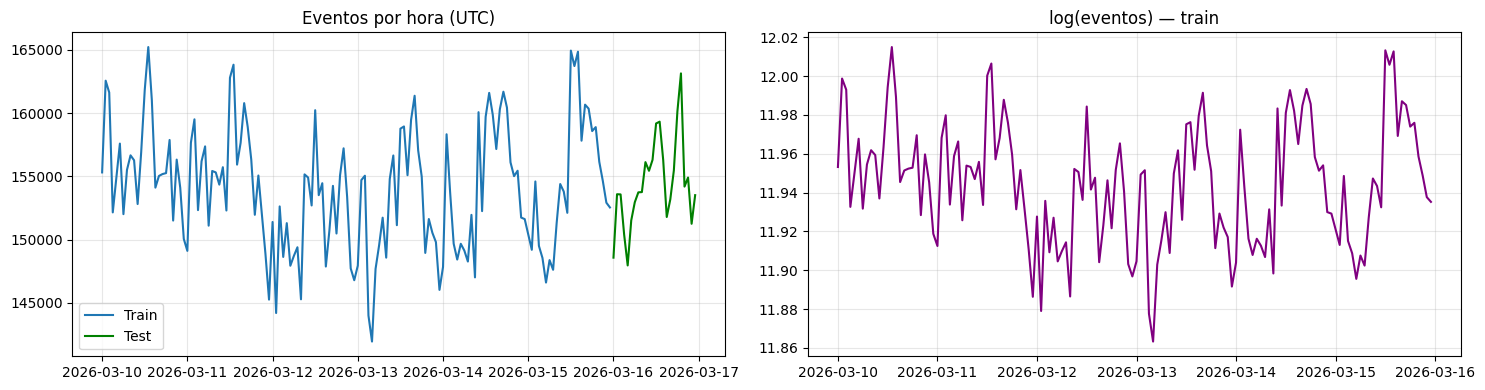

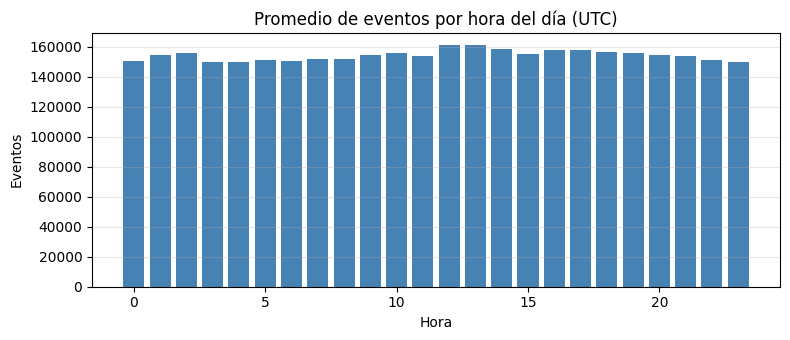

Observaciones: 168 | Train: 144 | Test: 24 | Primer instante: 2026-03-10 00:00:00


In [4]:
valores = [v for d in dias for v in conteos[d]["horas"]]
idx = pd.date_range(f"{FECHA_INICIO} 00:00", periods=len(valores), freq="h")
ts = pd.Series(valores, index=idx, name="eventos", dtype=float)
assert ts.isna().sum() == 0 and (ts > 0).all(), "Hay horas sin eventos: revisa los archivos."
assert len(ts) == N_DIAS * 24

train, test = ts.iloc[:-H], ts.iloc[-H:]
train_log = np.log(train)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(train, label="Train"); axes[0].plot(test, color="green", label="Test")
axes[0].set_title("Eventos por hora (UTC)"); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].plot(train_log, color="purple"); axes[1].set_title("log(eventos) — train"); axes[1].grid(alpha=.3)
plt.tight_layout(); guardar("01_serie_y_log"); plt.show()

perfil = ts.groupby(ts.index.hour).mean()
fig = plt.figure(figsize=(8, 3.5)); plt.bar(perfil.index, perfil.values, color="steelblue")
plt.title("Promedio de eventos por hora del día (UTC)"); plt.xlabel("Hora"); plt.ylabel("Eventos"); plt.grid(alpha=.3, axis="y")
plt.tight_layout(); guardar("02_perfil_horario"); plt.show()

print(f"Observaciones: {len(ts)} | Train: {len(train)} | Test: {len(test)} | Primer instante: {ts.index[0]}")
M["datos"] = {
    "fuente": "GH Archive (data.gharchive.org), archivos diarios .json.gz",
    "carpeta": str(CARPETA), "fecha_inicio": FECHA_INICIO, "n_dias": N_DIAS,
    "frecuencia": "horaria (UTC)", "observaciones": len(ts), "train_n": len(train), "test_n": len(test),
    "periodo_estacional_s": S, "horizonte_H": H, "total_eventos": int(ts.sum()),
    "eventos_por_dia": {f"{d:%Y-%m-%d}": int(sum(conteos[d]["horas"])) for d in dias},
    "metodo_conteo_por_dia": {f"{d:%Y-%m-%d}": {k: v for k, v in conteos[d].items() if k not in ("horas", "archivo", "bytes")} for d in dias},
    "eventos_por_hora": {"min": int(ts.min()), "max": int(ts.max()), "media": float(ts.mean())},
}

## Etapa 1 — Identificación (Cap. 6.1, 6.1.1 y 6.2)

### 1.1 No estacionariedad y diferenciación: ¿hace falta $D$?
Con ciclo diario, la diferencia estacional $\nabla_{24} y_t = y_t - y_{t-24}$ elimina el patrón repetitivo. Para decidir $D$ se mide la **fuerza estacional** con STL (Wang, Smith & Hyndman, 2006): $F_s=\max\left(0,\,1-\frac{Var(R_t)}{Var(S_t+R_t)}\right)$; con $F_s>0{,}64$ se toma $D=1$ (regla de `nsdiffs` en R).

Fuerza estacional Fs = 0.704  ->  D = 1


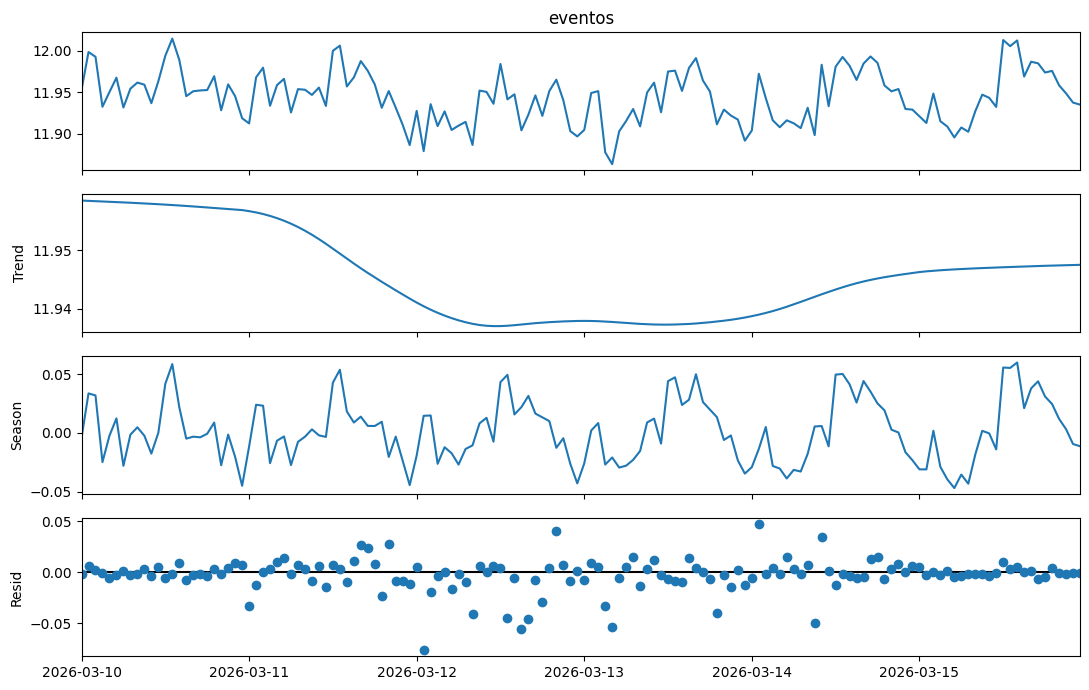

In [5]:
stl = STL(train_log, period=S, robust=True).fit()
Fs = max(0.0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
D = 1 if Fs > 0.64 else 0
print(f"Fuerza estacional Fs = {Fs:.3f}  ->  D = {D}")
fig = stl.plot(); fig.set_size_inches(11, 7)
plt.tight_layout(); guardar("03_stl_descomposicion"); plt.show()
M["identificacion"] = {"fuerza_estacional_Fs": float(Fs), "umbral_Fs": 0.64, "D": D}

### 1.2 Prueba de raíz unitaria de Dickey–Fuller (aumentada) y KPSS → $d$
- **ADF:** $H_0$: hay raíz unitaria (no estacionaria). Queremos **rechazar** ($p<0{,}05$).
- **KPSS:** $H_0$: la serie es estacionaria. Queremos **no rechazar** ($p>0{,}05$).

Se concluye estacionariedad solo si **ambas** coinciden. Se prueba la serie en niveles, con $D$ y, si hace falta, con $d=1$.

log(serie) en niveles                    ADF p=0.0000 | KPSS p=0.1000 -> estacionaria
log(serie) con D=1                       ADF p=0.0000 | KPSS p=0.0143 -> NO estacionaria
log(serie) con D=1, d=1                  ADF p=0.0000 | KPSS p=0.1000 -> estacionaria

=> d = 1, D = 1, s = 24
Media de la serie diferenciada = 0.00039 (t ingenuo = 0.12); por eso la deriva se evalúa en la grilla.


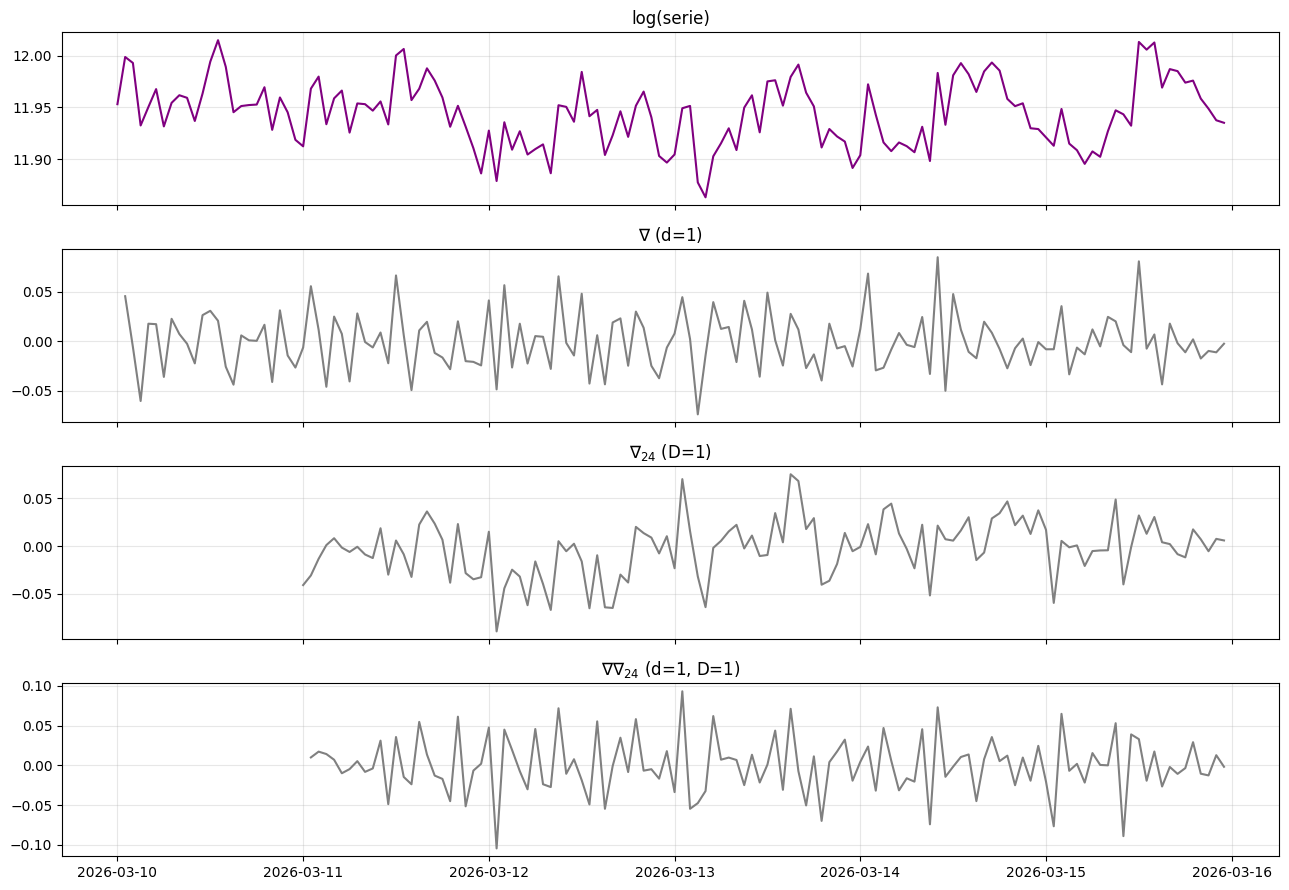

In [6]:
def pruebas_estacionariedad(x, nombre):
    x = x.dropna()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", FutureWarning)
        warnings.simplefilter("ignore", InterpolationWarning)
        adf = adfuller(x, autolag="AIC")
        kp = kpss(x, regression="c", nlags="auto")
    ok = (adf[1] < ALPHA) and (kp[1] > ALPHA)
    print(f"{nombre:<40} ADF p={adf[1]:.4f} | KPSS p={kp[1]:.4f} -> {'estacionaria' if ok else 'NO estacionaria'}")
    return {"serie": nombre, "n": int(len(x)),
            "ADF_estadistico": float(adf[0]), "ADF_p": float(adf[1]), "ADF_rezagos": int(adf[2]),
            "ADF_valores_criticos": {k: float(v) for k, v in adf[4].items()},
            "KPSS_estadistico": float(kp[0]), "KPSS_p": float(kp[1]), "estacionaria": bool(ok)}

pruebas = [pruebas_estacionariedad(train_log, "log(serie) en niveles")]
x = train_log.diff(S) if D == 1 else train_log
pruebas.append(pruebas_estacionariedad(x, f"log(serie) con D={D}"))
if pruebas[-1]["estacionaria"]:
    d = 0
else:
    pruebas.append(pruebas_estacionariedad(x.diff(1), f"log(serie) con D={D}, d=1"))
    d = 1
serie_est = x.diff(1).dropna() if d == 1 else x.dropna()
print(f"\n=> d = {d}, D = {D}, s = {S}")

t_media = serie_est.mean() / (serie_est.std(ddof=1) / np.sqrt(len(serie_est)))
print(f"Media de la serie diferenciada = {serie_est.mean():.5f} (t ingenuo = {t_media:.2f}); por eso la deriva se evalúa en la grilla.")

fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
axes[0].plot(train_log, color="purple"); axes[0].set_title("log(serie)")
axes[1].plot(train_log.diff(1), color="gray"); axes[1].set_title(r"$\nabla$ (d=1)")
axes[2].plot(train_log.diff(S), color="gray"); axes[2].set_title(rf"$\nabla_{{{S}}}$ (D=1)")
axes[3].plot(train_log.diff(S).diff(1), color="gray"); axes[3].set_title(rf"$\nabla\nabla_{{{S}}}$ (d=1, D=1)")
for a in axes: a.grid(alpha=.3)
plt.tight_layout(); guardar("04_diferenciaciones"); plt.show()

M["identificacion"].update({"d": d, "pruebas_estacionariedad": pruebas,
                            "media_serie_diferenciada": float(serie_est.mean()), "t_ingenuo_media": float(t_media)})

### 1.3 ACF y PACF de la serie estacionaria (Box–Jenkins)
Rezagos 1–6 sugieren $p,q$ regulares; los múltiplos de 24 (24, 48) sugieren $P,Q$ estacionales. Esto **acota la grilla** de la etapa 2.

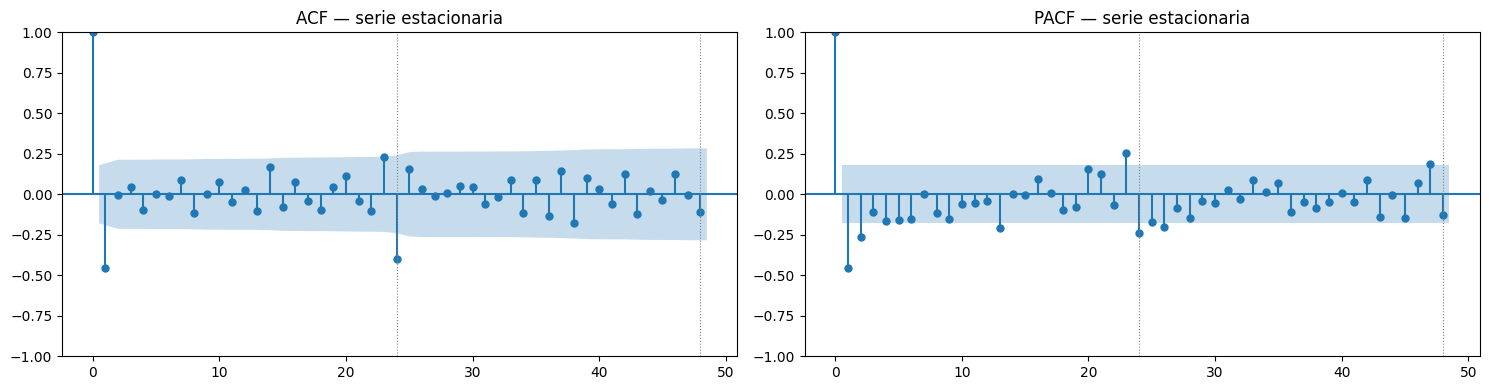

In [7]:
nl = max(S + 1, min(2 * S, len(serie_est) // 2 - 1))
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
plot_acf(serie_est, lags=nl, ax=axes[0], title="ACF — serie estacionaria")
plot_pacf(serie_est, lags=nl, ax=axes[1], title="PACF — serie estacionaria", method="ywm")
for ax in axes:
    for k in range(S, nl + 1, S): ax.axvline(k, color="gray", ls=":", lw=.8)
plt.tight_layout(); guardar("05_acf_pacf"); plt.show()

## Etapa 2 — Estimación (Cap. 6.2 y 6.4)

Grilla sistemática: $p,q\in\{0,1,2\}$, $P,Q\in\{0,1\}$, deriva `trend`$\in\{$ninguna, constante$\}$, con $d$, $D$ y $s=24$ fijos, de modo que los modelos son comparables por AIC/BIC. Se mantienen `enforce_stationarity` y `enforce_invertibility`; se registra la convergencia de cada ajuste y los no convergidos se descartan.

⏱️ Con `RAPIDO=False` son 72 ajustes con $s=24$; puede tardar varios minutos.

In [8]:
rango_pq = [0, 1] if RAPIDO else [0, 1, 2]
filas = []
t0 = time.time()
for p, q, P, Q, tr in tqdm(list(product(rango_pq, rango_pq, [0, 1], [0, 1], ["n", "c"])), desc="Ajustando SARIMA"):
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        try:
            res = SARIMAX(train_log, order=(p, d, q), seasonal_order=(P, D, Q, S), trend=tr).fit(disp=False, maxiter=300)
            filas.append(dict(order=(p, d, q), seasonal=(P, D, Q, S), trend=tr, k_arma=p + q + P + Q,
                              AIC=res.aic, BIC=res.bic, convergio=bool(res.mle_retvals.get("converged", True)),
                              n_warn=len(w), res=res))
        except Exception as e:
            filas.append(dict(order=(p, d, q), seasonal=(P, D, Q, S), trend=tr, k_arma=p + q + P + Q,
                              AIC=np.nan, BIC=np.nan, convergio=False, n_warn=len(w), res=None))
print(f"Tiempo: {(time.time() - t0) / 60:.1f} min")

df = pd.DataFrame(filas)
print(f"Modelos ajustados: {len(df)} | no convergidos o con error: {(~df.convergio).sum()}")
validos = df[df.convergio & df.AIC.notna()].sort_values("AIC").reset_index(drop=True)
assert len(validos) > 0, "Ningún modelo convergió: revisa d, D o la grilla."
display(validos[["order", "seasonal", "trend", "AIC", "BIC", "n_warn"]].head(10))

def _fila_json(f):
    return {"order": list(f["order"]), "seasonal": list(f["seasonal"]), "trend": f["trend"],
            "AIC": f["AIC"], "BIC": f["BIC"], "convergio": f["convergio"], "n_warn": f["n_warn"]}
M["estimacion"] = {"modelos_ajustados": int(len(df)), "no_convergidos_o_con_error": int((~df.convergio).sum()),
                   "grilla": {"p_q": rango_pq, "P_Q": [0, 1], "trend": ["n", "c"]},
                   "top10_por_AIC": [_fila_json(r) for r in validos.head(10).to_dict("records")]}
(TAB / "grilla_completa.json").write_text(json.dumps(
    [_fila_json(r) for r in df.drop(columns="res").assign(res=None).to_dict("records")], default=float))

Ajustando SARIMA:   0%|          | 0/72 [00:00<?, ?it/s]

Tiempo: 6.7 min
Modelos ajustados: 72 | no convergidos o con error: 5


,order,seasonal,trend,AIC,BIC,n_warn
0,"(1, 1, 1)","(0, 1, 1, 24)",c,-544.924788,-531.029171,0
1,"(2, 1, 1)","(1, 1, 1, 24)",c,-542.725716,-523.271851,0
2,"(0, 1, 1)","(0, 1, 1, 24)",n,-542.673760,-534.336390,0
3,"(0, 1, 2)","(0, 1, 1, 24)",n,-541.465268,-530.348774,0
4,"(1, 1, 1)","(0, 1, 1, 24)",n,-541.443876,-530.327382,0
5,"(1, 1, 1)","(1, 1, 1, 24)",c,-541.199081,-524.524340,0
6,"(0, 1, 2)","(1, 1, 1, 24)",c,-540.886057,-524.211316,0
7,"(0, 1, 1)","(1, 1, 1, 24)",n,-540.657312,-529.540818,0
8,"(2, 1, 1)","(0, 1, 1, 24)",n,-540.144933,-526.249316,0
9,"(1, 1, 1)","(1, 1, 1, 24)",n,-539.552996,-525.657378,0


10740

## Etapa 3 — Diagnóstico de residuos y ciclo iterativo (Cap. 6.2)

Se recorren los candidatos **en orden de AIC** y se queda el primero que pase:
1. **Ljung–Box** sobre residuos sin los primeros $d + D\cdot s$ (inicialización difusa) y con `model_df` = nº de parámetros ARMA.
2. **Alerta de sobrediferenciación:** coeficiente MA estacional cercano a $-1$.

Además se informan normalidad (Jarque–Bera) y homocedasticidad.

In [9]:
burn = d + D * S

def diagnosticar(fila, lags=(24, 36)):
    res = fila.res
    r = res.resid.iloc[burn:]
    out = {}
    for L in lags:
        lb = acorr_ljungbox(r, lags=[L], model_df=fila.k_arma)
        out[f"LB_p(lag={L})"] = float(lb["lb_pvalue"].iloc[0])
    out["JB_p"] = float(jarque_bera(r)[1])
    try:
        out["Heterosc_p"] = float(res.test_heteroskedasticity(method="breakvar")[0][1])
    except Exception:
        out["Heterosc_p"] = np.nan
    ma_est = [v for k, v in res.params.items() if k.startswith("ma.S.")]
    out["sobrediff"] = bool(any(v < -0.95 for v in ma_est))
    out["pasa_LB"] = bool(all(out[f"LB_p(lag={L})"] > ALPHA for L in lags))
    return out

diag = []
for i, fila in validos.head(15).iterrows():
    diag.append({"Modelo": f"SARIMA{fila.order}{fila.seasonal} trend={fila.trend}", "AIC": fila.AIC, **diagnosticar(fila)})
df_diag = pd.DataFrame(diag)
display(df_diag.round(4))

aprobados = df_diag[df_diag.pasa_LB & ~df_diag.sobrediff]
if len(aprobados):
    idx_ok = aprobados.index[0]; ninguno = False
    print(f"\n-> Modelo elegido (menor AIC que pasa el diagnóstico): {df_diag.loc[idx_ok, 'Modelo']}")
else:
    idx_ok = 0; ninguno = True
    print("\n-> ATENCIÓN: ningún candidato pasa el diagnóstico. Se usa el de menor AIC; "
          "hay que volver a la etapa 1 (revisar transformación, d, D o ampliar la grilla).")

fila_elegida = validos.loc[idx_ok]
mejor = fila_elegida.res
print(mejor.summary().tables[1])

M["diagnostico"] = {"criterio": "menor AIC que pasa Ljung-Box (lags 24 y 36, model_df=p+q+P+Q) y sin sobrediferenciación",
                    "ningun_candidato_aprobado": ninguno, "modelo_elegido": df_diag.loc[idx_ok, "Modelo"],
                    "tabla": df_diag.round(6).to_dict("records")}
M["modelo_final"] = {"order": list(fila_elegida.order), "seasonal_order": list(fila_elegida.seasonal), "trend": fila_elegida.trend,
                     "AIC": float(mejor.aic), "BIC": float(mejor.bic), "nobs": int(mejor.nobs),
                     "parametros": {k: {"coef": float(mejor.params[k]), "error_est": float(mejor.bse[k]), "p_valor": float(mejor.pvalues[k])}
                                    for k in mejor.params.index}}
(TAB / "resumen_modelo_final.txt").write_text(mejor.summary().as_text())

,Modelo,AIC,LB_p(lag=24),LB_p(lag=36),JB_p,Heterosc_p,sobrediff,pasa_LB
0,"SARIMA(1, 1, 1)(0, 1, 1, 24) trend=c",-544.9248,0.8064,0.8320,0.0000,0.2653,False,True
1,"SARIMA(2, 1, 1)(1, 1, 1, 24) trend=c",-542.7257,0.7270,0.8497,0.0003,0.2423,True,True
2,"SARIMA(0, 1, 1)(0, 1, 1, 24) trend=n",-542.6738,0.8245,0.7462,0.0102,0.3201,True,True
3,"SARIMA(0, 1, 2)(0, 1, 1, 24) trend=n",-541.4653,0.8388,0.7816,0.0013,0.3778,True,True
4,"SARIMA(1, 1, 1)(0, 1, 1, 24) trend=n",-541.4439,0.8311,0.8005,0.0003,0.3460,False,True
5,"SARIMA(1, 1, 1)(1, 1, 1, 24) trend=c",-541.1991,0.7460,0.8268,0.0002,0.3843,False,True
6,"SARIMA(0, 1, 2)(1, 1, 1, 24) trend=c",-540.8861,0.6571,0.5710,0.0000,0.3628,False,True
7,"SARIMA(0, 1, 1)(1, 1, 1, 24) trend=n",-540.6573,0.7831,0.7065,0.0108,0.3321,False,True
8,"SARIMA(2, 1, 1)(0, 1, 1, 24) trend=n",-540.1449,0.7808,0.8526,0.0005,0.3368,False,True
9,"SARIMA(1, 1, 1)(1, 1, 1, 24) trend=n",-539.5530,0.8008,0.7756,0.0005,0.3782,False,True



-> Modelo elegido (menor AIC que pasa el diagnóstico): SARIMA(1, 1, 1)(0, 1, 1, 24) trend=c
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0002   7.39e-05      3.366      0.001       0.000       0.000
ar.L1          0.2810      0.109      2.580      0.010       0.068       0.495
ma.L1         -0.9780      0.094    -10.420      0.000      -1.162      -0.794
ma.S.L24      -0.9439      0.853     -1.106      0.269      -2.616       0.728
sigma2         0.0004      0.000      1.228      0.219      -0.000       0.001


2051

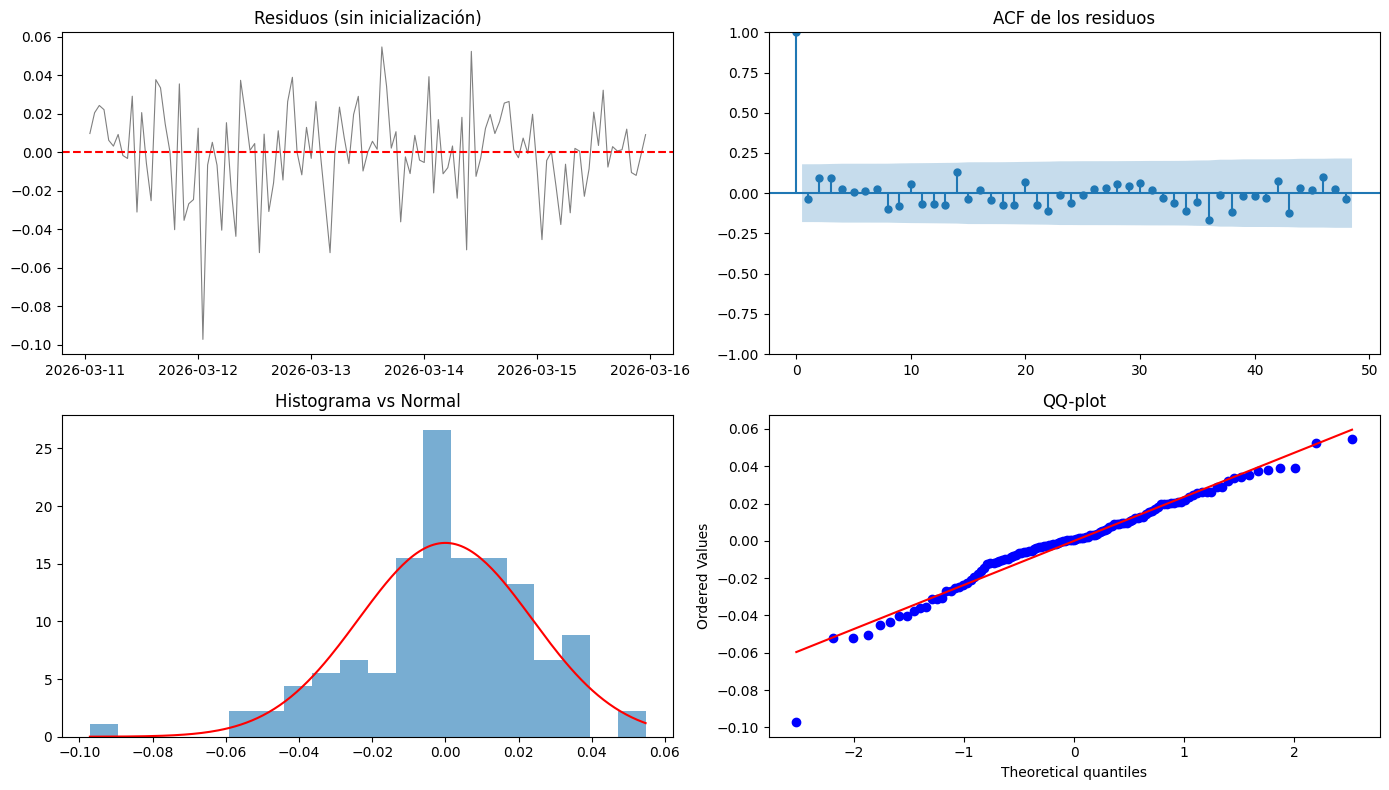

LB_p(lag=24)    0.806358
LB_p(lag=36)    0.832002
JB_p            0.000019
Heterosc_p      0.265329


In [10]:
residuos = mejor.resid.iloc[burn:]
nl_r = max(S + 1, min(2 * S, len(residuos) // 2 - 1))
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes[0, 0].plot(residuos, color="gray", lw=.8); axes[0, 0].axhline(0, color="red", ls="--"); axes[0, 0].set_title("Residuos (sin inicialización)")
plot_acf(residuos, lags=nl_r, ax=axes[0, 1], title="ACF de los residuos")
axes[1, 0].hist(residuos, bins=20, density=True, alpha=.6)
xs = np.linspace(residuos.min(), residuos.max(), 200)
axes[1, 0].plot(xs, stats.norm.pdf(xs, residuos.mean(), residuos.std()), "r"); axes[1, 0].set_title("Histograma vs Normal")
stats.probplot(residuos, dist="norm", plot=axes[1, 1]); axes[1, 1].set_title("QQ-plot")
plt.tight_layout(); guardar("06_diagnostico_residuos"); plt.show()
print(df_diag.loc[idx_ok, ["LB_p(lag=24)", "LB_p(lag=36)", "JB_p", "Heterosc_p"]].round(4).to_string())

## Etapa 4 — Pronóstico (Cap. 6.3 y 6.4) y comparación

Se comparan tres pronósticos de las **24 horas de prueba**:
- **SARIMA** elegido (con estacionalidad $s=24$) — sección 6.4.
- **ARIMA no estacional** (mejor $(p,d,q)$ por AIC, sin parte estacional) — sección 6.3. Sirve para mostrar qué aporta la parte estacional.
- **Benchmark estacional ingenuo:** $\hat y_{t+h}=y_{t+h-24}$ (repetir el último día observado).

El modelo trabaja en logaritmos: el pronóstico y el intervalo de **predicción al 95 %** se exponencian para volver a la escala original (equivale a la mediana condicional).

log(serie), ARIMA, d=0                   ADF p=0.0000 | KPSS p=0.1000 -> estacionaria
ARIMA no estacional elegido: ARIMA(2, 0, 0) trend=c (AIC=-641.2)


,MAE,RMSE,MAPE,MASE
SARIMA,4847.261,5627.000,3.144,1.383
ARIMA no estacional,2515.819,3424.180,1.617,0.718
Naive estacional (y_{t-24}),3418.542,4111.824,2.207,0.975


Cobertura empírica del intervalo de predicción 95 %: 71 % de las 24 horas de test
Mejora del MAE de SARIMA frente al naive estacional: -41.8 %


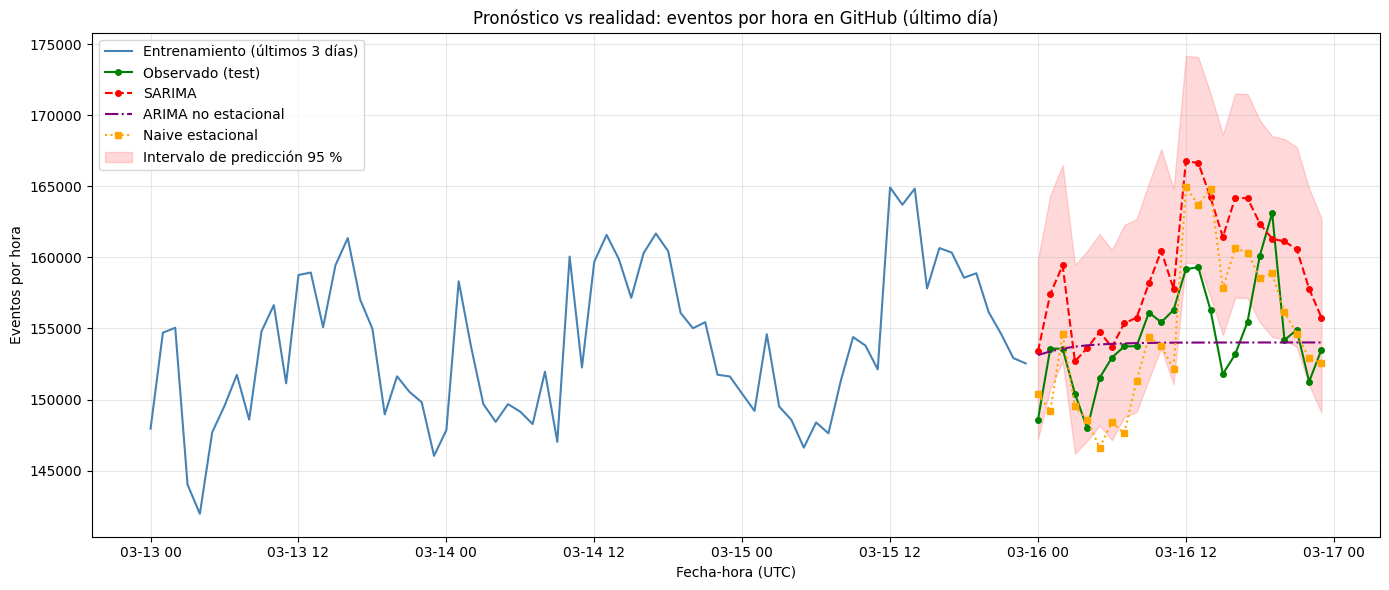

In [11]:
# --- ARIMA no estacional (6.3): d por ADF+KPSS sobre log(serie) ---
d_ar = 0
x_ar = train_log
while d_ar < 2 and not pruebas_estacionariedad(x_ar, f"log(serie), ARIMA, d={d_ar}")["estacionaria"]:
    d_ar += 1; x_ar = train_log.diff(d_ar)
filas_ar = []
for p, q, tr in product([0, 1, 2, 3], [0, 1, 2, 3], ["n", "c"]):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            r_ = SARIMAX(train_log, order=(p, d_ar, q), trend=tr).fit(disp=False, maxiter=300)
            if bool(r_.mle_retvals.get("converged", True)):
                filas_ar.append(dict(order=(p, d_ar, q), trend=tr, AIC=r_.aic, res=r_))
        except Exception:
            pass
fila_ar = min(filas_ar, key=lambda f: f["AIC"])
arima = fila_ar["res"]
print(f"ARIMA no estacional elegido: ARIMA{fila_ar['order']} trend={fila_ar['trend']} (AIC={arima.aic:.1f})")

# --- Pronósticos ---
fc = mejor.get_forecast(steps=H)
pred = np.exp(fc.predicted_mean); ci = np.exp(fc.conf_int(alpha=ALPHA))
pred.index = ci.index = test.index
fc_ar = arima.get_forecast(steps=H)
pred_ar = np.exp(fc_ar.predicted_mean); pred_ar.index = test.index
naive = pd.Series(np.tile(train.iloc[-S:].values, int(np.ceil(H / S)))[:H], index=test.index)

def metricas(y, yhat):
    return dict(MAE=float(mean_absolute_error(y, yhat)), RMSE=float(np.sqrt(mean_squared_error(y, yhat))),
                MAPE=float(np.mean(np.abs((y - yhat) / y)) * 100))

escala = np.mean(np.abs(train.values[S:] - train.values[:-S]))     # MAE in-sample del naive estacional
tabla = pd.DataFrame({"SARIMA": metricas(test, pred), "ARIMA no estacional": metricas(test, pred_ar),
                      "Naive estacional (y_{t-24})": metricas(test, naive)}).T
tabla["MASE"] = [np.mean(np.abs(test - p_)) / escala for p_ in (pred, pred_ar, naive)]
display(tabla.round(3))

cobertura = float(((test >= ci.iloc[:, 0]) & (test <= ci.iloc[:, 1])).mean() * 100)
mejora = float((tabla.loc["Naive estacional (y_{t-24})", "MAE"] - tabla.loc["SARIMA", "MAE"]) / tabla.loc["Naive estacional (y_{t-24})", "MAE"] * 100)
print(f"Cobertura empírica del intervalo de predicción 95 %: {cobertura:.0f} % de las {H} horas de test")
print(f"Mejora del MAE de SARIMA frente al naive estacional: {mejora:.1f} %")

fig = plt.figure(figsize=(14, 6))
plt.plot(train.index[-3 * S:], train.values[-3 * S:], label="Entrenamiento (últimos 3 días)", color="steelblue")
plt.plot(test.index, test.values, label="Observado (test)", color="green", marker="o", ms=4)
plt.plot(pred.index, pred.values, "r--", marker="o", ms=4, label="SARIMA")
plt.plot(pred_ar.index, pred_ar.values, color="purple", ls="-.", label="ARIMA no estacional")
plt.plot(naive.index, naive.values, color="orange", ls=":", marker="s", ms=4, label="Naive estacional")
plt.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color="red", alpha=.15, label="Intervalo de predicción 95 %")
plt.title("Pronóstico vs realidad: eventos por hora en GitHub (último día)")
plt.xlabel("Fecha-hora (UTC)"); plt.ylabel("Eventos por hora"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); guardar("07_pronostico"); plt.show()

M["pronostico"] = {
    "horizonte_horas": H, "escala_MASE": float(escala),
    "arima_no_estacional": {"order": list(fila_ar["order"]), "trend": fila_ar["trend"], "AIC": float(arima.aic)},
    "metricas": {k: {m: float(v) for m, v in fila.items()} for k, fila in tabla.to_dict("index").items()},
    "cobertura_IC95_pct": cobertura, "mejora_MAE_sarima_vs_naive_pct": mejora,
    "sarima_supera_naive_en_MAE": bool(mejora > 0), "MASE_sarima_menor_a_1": bool(tabla.loc["SARIMA", "MASE"] < 1),
    "valores": [{"hora_utc": str(t), "observado": float(test[t]), "sarima": float(pred[t]), "ic95_inf": float(ci.iloc[i, 0]),
                 "ic95_sup": float(ci.iloc[i, 1]), "arima": float(pred_ar[t]), "naive": float(naive[t])} for i, t in enumerate(test.index)],
}

## 5. Guardar todo y descargarlo

Crea en `resultados_sarima/`: las **figuras PNG** (ya guardadas al mostrarse), `metricas.json`, la serie horaria en JSON, las tablas, el resumen del modelo y el modelo ajustado; lo comprime en `resultados_sarima.zip` y lo descarga a tu computadora. Con `COPIAR_A_DRIVE=True` deja también una copia en Drive.

In [12]:
def limpiar(o):
    if isinstance(o, dict):  return {str(k): limpiar(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [limpiar(v) for v in o]
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (float, np.floating)): return None if not np.isfinite(o) else float(o)
    return o

M["entorno"] = {"generado_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"), "python": platform.python_version(),
                "numpy": np.__version__, "pandas": pd.__version__, "statsmodels": statsmodels.__version__,
                "scipy": scipy.__version__, "scikit_learn": sklearn.__version__}
M["archivos_generados"] = sorted(str(p.relative_to(RES)) for p in RES.rglob("*") if p.is_file())

(RES / "metricas.json").write_text(json.dumps(limpiar(M), ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
(TAB / "serie_horaria.json").write_text(json.dumps(
    [{"hora_utc": str(t), "eventos": int(v), "conjunto": "train" if t in train.index else "test"} for t, v in ts.items()], indent=1))
(TAB / "comparacion_pronosticos.json").write_text(json.dumps(limpiar(M["pronostico"]["metricas"]), indent=2))
try:
    mejor.save(str(RES / "modelo_sarima.pkl"), remove_data=True)
except Exception as e:
    print("No se pudo guardar el modelo (no es grave):", e)
(RES / "LEEME.txt").write_text(
    "DAT-262 Cap. 6 — SARIMA sobre eventos por hora de GH Archive (7 días)\n"
    "metricas.json            : todos los resultados numéricos (datos, pruebas ADF/KPSS, modelo, diagnóstico, pronóstico)\n"
    "figuras/                 : imágenes PNG de cada etapa (01_ ... 07_)\n"
    "tablas/                  : serie horaria, grilla completa, comparación de pronósticos, resumen del modelo final\n"
    "modelo_sarima.pkl        : modelo final (statsmodels: SARIMAXResults.load)\n", encoding="utf-8")

ruta_zip = shutil.make_archive(str(BASE / NOMBRE_RES), "zip", root_dir=RES.parent, base_dir=RES.name)
print(f"Carpeta: {RES.resolve()}\nZIP:     {ruta_zip}  ({Path(ruta_zip).stat().st_size / 1024:,.0f} KB)")
for p in sorted(RES.rglob("*")):
    if p.is_file(): print("  ", p.relative_to(RES))

if COPIAR_A_DRIVE and EN_COLAB:
    try:
        destino = CARPETA.parent / NOMBRE_RES
        shutil.copytree(RES, destino, dirs_exist_ok=True)
        print("Copia en Drive:", destino)
    except Exception as e:
        print("No pude copiar a Drive:", e)
if DESCARGAR_ZIP and EN_COLAB:
    from google.colab import files
    files.download(ruta_zip)

Carpeta: /content/resultados_sarima
ZIP:     /content/resultados_sarima.zip  (6,104 KB)
   LEEME.txt
   figuras/01_serie_y_log.png
   figuras/02_perfil_horario.png
   figuras/03_stl_descomposicion.png
   figuras/04_diferenciaciones.png
   figuras/05_acf_pacf.png
   figuras/06_diagnostico_residuos.png
   figuras/07_pronostico.png
   metricas.json
   modelo_sarima.pkl
   tablas/comparacion_pronosticos.json
   tablas/grilla_completa.json
   tablas/resumen_modelo_final.txt
   tablas/serie_horaria.json
Copia en Drive: /content/drive/MyDrive/DAT-262 procesos estocasticos y series/resultados_sarima


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusiones (para el informe)

- **MASE < 1** y **MAE de SARIMA menor que el del naive estacional** indican que el modelo aporta más que repetir el día anterior. Los valores están en `metricas.json → pronostico`.
- La comparación **SARIMA vs. ARIMA no estacional** muestra qué aporta la parte estacional ($s=24$) a este tipo de serie.
- Con 7 días solo hay **7 ciclos diarios**: la estimación de $P$, $Q$ y de los parámetros estacionales es poco precisa y el test es un solo día. Una validación más sólida sería **rolling-origin** o ampliar el rango de días.
- Los días 14–15 de marzo son sábado y domingo (una sola semana laboral/fin de semana): el ciclo semanal no se puede modelar con tan pocos días, por eso $s=24$ y no $s=168$.
- Revisar eventos atípicos (caídas o picos de GH Archive).